In [1]:

from pathlib import Path
import rasterio
import numpy as np

data_dir = Path.cwd().parent / "data" / "raw" if Path.cwd().name == "notebooks" else Path.cwd() / "data" / "raw"
print("Datasets found:", len(list(data_dir.glob("*.tif"))))

for file in sorted(data_dir.glob("*.tif")):
    with rasterio.open(file) as src:
        image = src.read()
        valid = np.isfinite(image).all(axis=0)
        labels = image[2]
        usable = valid & (labels >= 0)

        print(f"\nDataset: {file.name}")
        print(f"Shape: {image.shape}")
        print(f"Resolution: {src.res}")
        print(f"CRS: {src.crs}")
        print(f"Valid labeled pixels: {usable.sum():,}")
        print(f"Classes: {np.unique(labels[usable]).astype(int)}")


Datasets found: 10

Dataset: Bastogne_June2025.tif
Shape: (3, 523, 521)
Resolution: (10.0, 10.0)
CRS: EPSG:32632
Valid labeled pixels: 135,313
Classes: [0 1 2 4 6 8]

Dataset: Bastogne_March2025.tif
Shape: (3, 523, 521)
Resolution: (10.0, 10.0)
CRS: EPSG:32632
Valid labeled pixels: 147,674
Classes: [0 1 2 4 6 8]

Dataset: Bastogne_September2025.tif
Shape: (3, 523, 521)
Resolution: (10.0, 10.0)
CRS: EPSG:32632
Valid labeled pixels: 139,764
Classes: [0 1 2 4 6 8]

Dataset: Dudelange_June2025_Test.tif
Shape: (3, 520, 519)
Resolution: (10.0, 10.0)
CRS: EPSG:32632
Valid labeled pixels: 250,469
Classes: [0 1 2 4 5 6 7]

Dataset: Dudelange_March2025.tif
Shape: (3, 520, 519)
Resolution: (10.0, 10.0)
CRS: EPSG:32632
Valid labeled pixels: 173,101
Classes: [0 1 2 4 5 6 7]

Dataset: Dudelange_September2025.tif
Shape: (3, 520, 519)
Resolution: (10.0, 10.0)
CRS: EPSG:32632
Valid labeled pixels: 172,443
Classes: [0 1 2 4 6 7]

Dataset: Thionville_December2025.tif
Shape: (3, 520, 518)
Resolution: (10.

In [2]:

for file in sorted(data_dir.glob("*.tif")):
    with rasterio.open(file) as src:
        data = src.read()
        valid_sar = np.isfinite(data[:2]).all(axis=0)
        labels = data[2]
        usable = valid_sar & np.isfinite(labels) & (labels >= 0) & (labels <= 8)

        print(
            file.name,
            "| Usable:", int(usable.sum()),
            "| Ignored:", int(data.shape[1] * data.shape[2] - usable.sum())
        )


Bastogne_June2025.tif | Usable: 135313 | Ignored: 137170
Bastogne_March2025.tif | Usable: 147674 | Ignored: 124809
Bastogne_September2025.tif | Usable: 139764 | Ignored: 132719
Dudelange_June2025_Test.tif | Usable: 250469 | Ignored: 19411
Dudelange_March2025.tif | Usable: 173101 | Ignored: 96779
Dudelange_September2025.tif | Usable: 172443 | Ignored: 97437
Thionville_December2025.tif | Usable: 148041 | Ignored: 121319
Thionville_June2025.tif | Usable: 250443 | Ignored: 18917
Thionville_March2025.tif | Usable: 212729 | Ignored: 56631
Thionville_September2025.tif | Usable: 192333 | Ignored: 77027


In [3]:

for file in sorted(data_dir.glob("*.tif")):
    with rasterio.open(file) as src:
        sar = src.read([1, 2])

    valid = np.isfinite(sar).all(axis=0)

    print(
        file.name,
        "| VV:", np.round(np.percentile(sar[0][valid], [1, 99]), 2),
        "| VH:", np.round(np.percentile(sar[1][valid], [1, 99]), 2)
    )


Bastogne_June2025.tif | VV: [-17.5    0.05] | VH: [-24.25  -7.24]
Bastogne_March2025.tif | VV: [-16.15   0.59] | VH: [-29.27  -6.91]
Bastogne_September2025.tif | VV: [-16.32   0.45] | VH: [-23.83  -7.23]
Dudelange_June2025_Test.tif | VV: [-15.82   2.39] | VH: [-22.44  -5.09]
Dudelange_March2025.tif | VV: [-15.63   2.92] | VH: [-24.43  -4.7 ]
Dudelange_September2025.tif | VV: [-15.55   2.79] | VH: [-22.56  -4.88]
Thionville_December2025.tif | VV: [-21.77   3.84] | VH: [-27.69  -3.5 ]
Thionville_June2025.tif | VV: [-21.18   3.36] | VH: [-27.8   -3.42]
Thionville_March2025.tif | VV: [-21.22   3.68] | VH: [-29.6   -3.26]
Thionville_September2025.tif | VV: [-21.85   3.59] | VH: [-28.16  -3.43]


In [4]:

file = data_dir / "Dudelange_June2025_Test.tif"

with rasterio.open(file) as src:
    sar = src.read([1, 2])

valid = np.isfinite(sar).all(axis=0)

# Fixed SAR dB clipping ranges
lower = np.array([-30, -35])[:, None, None]
upper = np.array([5, 0])[:, None, None]

normalized = (np.clip(sar, lower, upper) - lower) / (upper - lower)
normalized[:, ~valid] = 0

print("Normalized VV range:", normalized[0].min(), normalized[0].max())
print("Normalized VH range:", normalized[1].min(), normalized[1].max())
print("Invalid SAR pixels:", (~valid).sum())


Normalized VV range: 0.0 1.0
Normalized VH range: 0.0 1.0
Invalid SAR pixels: 19411


In [5]:

class_names = {
    0: "Water", 1: "Trees", 2: "Grass",
    3: "Flooded vegetation", 4: "Crops",
    5: "Shrub", 6: "Built-up",
    7: "Bare", 8: "Snow/Ice"
}

counts = np.zeros(9, dtype=np.int64)

for file in sorted(data_dir.glob("*.tif")):
    with rasterio.open(file) as src:
        data = src.read()

    valid = np.isfinite(data).all(axis=0)
    labels = data[2]
    valid &= (labels >= 0) & (labels <= 8)

    counts += np.bincount(
        labels[valid].astype(int), minlength=9
    )

for i, name in class_names.items():
    print(f"{name}: {counts[i]:,} ({counts[i]/counts.sum()*100:.2f}%)")


Water: 60,905 (3.34%)
Trees: 528,093 (28.98%)
Grass: 179,938 (9.87%)
Flooded vegetation: 283 (0.02%)
Crops: 145,403 (7.98%)
Shrub: 1,809 (0.10%)
Built-up: 902,265 (49.51%)
Bare: 3,483 (0.19%)
Snow/Ice: 131 (0.01%)


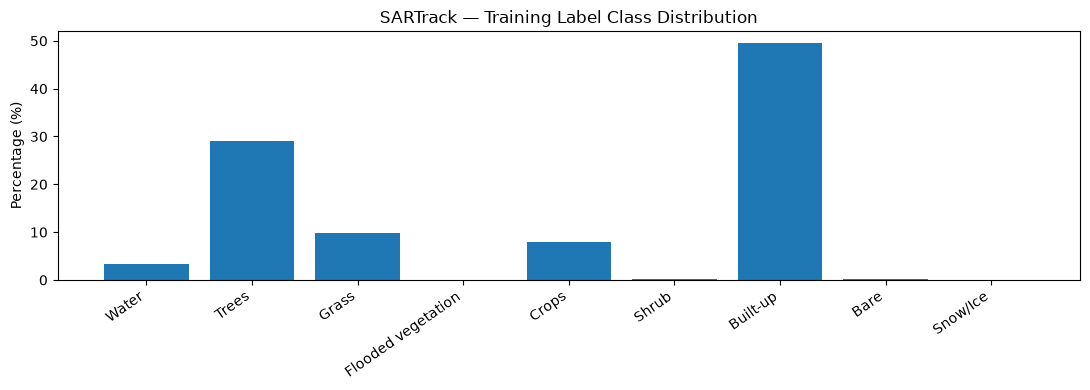

In [6]:

import matplotlib.pyplot as plt

names = [class_names[i] for i in range(9)]
percentages = counts / counts.sum() * 100

plt.figure(figsize=(11, 4))
plt.bar(names, percentages)
plt.xticks(rotation=35, ha="right")
plt.ylabel("Percentage (%)")
plt.title("SARTrack — Training Label Class Distribution")
plt.tight_layout()
plt.show()


In [7]:

# Original Dynamic World class → Baseline class
class_mapping = {
    0: 0,  # Water
    1: 1,  # Trees
    2: 2,  # Grass
    4: 3,  # Crops
    6: 4   # Built-up
}

mapped_counts = np.array([
    counts[0], counts[1], counts[2],
    counts[4], counts[6]
])

print("Baseline classes:", list(class_mapping.values()))
print("Pixels retained:", mapped_counts.sum())
print("Pixels ignored from rare classes:",
      counts.sum() - mapped_counts.sum())


Baseline classes: [0, 1, 2, 3, 4]
Pixels retained: 1816604
Pixels ignored from rare classes: 5706


In [8]:

train_files = sorted(
    list(data_dir.glob("Dudelange_*.tif")) +
    list(data_dir.glob("Bastogne_*.tif"))
)

val_files = sorted(data_dir.glob("Thionville_*.tif"))

print("Training datasets:", len(train_files))
print("Validation datasets:", len(val_files))
print("Overlap:", set(train_files) & set(val_files))
print("Test region: Esch/Belval (reserved)")


Training datasets: 6
Validation datasets: 4
Overlap: set()
Test region: Esch/Belval (reserved)


In [9]:

from pathlib import Path

output_dir = data_dir.parent / "processed"
patch_size = 128
stride = 64
ignore_index = 255

def create_patches(files, split):
    save_dir = output_dir / split
    save_dir.mkdir(parents=True, exist_ok=True)
    total = 0

    for file in files:
        with rasterio.open(file) as src:
            data = src.read()

        sar = data[:2]
        labels = data[2]

        valid = np.isfinite(sar).all(axis=0)
        valid &= np.isfinite(labels)

        x = (np.clip(sar, lower, upper) - lower) / (upper - lower)
        x = np.nan_to_num(x, nan=0, posinf=0, neginf=0).astype(np.float32)

        y = np.full(labels.shape, ignore_index, dtype=np.uint8)
        for original, mapped in class_mapping.items():
            y[valid & (labels == original)] = mapped

        h, w = labels.shape

        for row in range(0, h - patch_size + 1, stride):
            for col in range(0, w - patch_size + 1, stride):
                xp = x[:, row:row+patch_size, col:col+patch_size]
                yp = y[row:row+patch_size, col:col+patch_size]

                if np.mean(yp != ignore_index) < 0.25:
                    continue

                name = f"{file.stem}_{row}_{col}.npz"
                np.savez_compressed(save_dir / name, x=xp, y=yp)
                total += 1

    print(f"{split}: {total} patches saved")

create_patches(train_files, "train")
create_patches(val_files, "val")


train: 294 patches saved
val: 196 patches saved


In [10]:

for split in ["train", "val"]:
    files = sorted((output_dir / split).glob("*.npz"))

    with np.load(files[0]) as sample:
        x, y = sample["x"], sample["y"]

    print(f"{split}: {len(files)} patches")
    print("Image shape:", x.shape)
    print("Label shape:", y.shape)
    print("Normalized range:", x.min(), x.max())
    print("Classes:", np.unique(y))
    print()


train: 294 patches
Image shape: (2, 128, 128)
Label shape: (128, 128)
Normalized range: 0.0 0.9884602
Classes: [  1   2   3   4 255]

val: 196 patches
Image shape: (2, 128, 128)
Label shape: (128, 128)
Normalized range: 0.0 1.0
Classes: [  1   2   4 255]



In [11]:

for split in ["train", "val"]:
    class_counts = np.zeros(5, dtype=np.int64)
    ignored = 0

    for file in (output_dir / split).glob("*.npz"):
        with np.load(file) as sample:
            y = sample["y"]

        class_counts += np.bincount(
            y[y < 5].astype(int), minlength=5
        )
        ignored += np.sum(y == 255)

    print(f"\n{split.upper()}")
    for name, count in zip(
        ["Water", "Trees", "Grass", "Crops", "Built-up"],
        class_counts
    ):
        pct = 100 * count / max(class_counts.sum(), 1)
        print(f"{name}: {pct:.2f}%")

    print("Ignored pixels:", int(ignored))



TRAIN
Water: 0.62%
Trees: 36.07%
Grass: 13.47%
Crops: 9.46%
Built-up: 40.37%
Ignored pixels: 1592048

VAL
Water: 6.27%
Trees: 12.43%
Grass: 2.10%
Crops: 4.14%
Built-up: 75.05%
Ignored pixels: 685973
